# Phase 2B · 02 · XGBoost

**Goal:** replace the random forest with XGBoost, a different way of combining trees, and tune it the same way as notebook 01. The data, normalization and evaluation stay exactly as in Phase 2A. Then compare its AUC with the 2A forest (0.808) and the paper (0.84).

1. What boosting is, and the settings we search.
2. Nested cross-validation: tuning without ever seeing the test studies.
3. Unified evaluation, study-blocked 10×10 CV with the median.
4. Leave-one-study-out (LOSO).
5. Which settings won.
6. Experiment log (MLflow).

## Setup

Inputs come from notebook 1/03 (the 347 genera and the labels) and from the 2A tables (2A and paper AUCs for comparison). Outputs go to `results/figures/phase_2/phase_2b/02_xgboost/` and `results/tables/phase_2/phase_2b/02_xgboost/`.

`QUICK = True` runs 1 repeat instead of 10 and tries 4 settings instead of 10. It is only for checking that everything works, so it writes no tables and no MLflow record. The reported results come from `QUICK = False`, the paper's full 10×10 evaluation.

In [1]:
import os
import subprocess
import time
from pathlib import Path

os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.stats import loguniform, randint, uniform
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

QUICK = False
SEED = 2000
N_REPEATS = 1 if QUICK else 10
N_ITER = 4 if QUICK else 10
print(f"QUICK = {QUICK}: {N_REPEATS} repeat(s) of 10 folds, {N_ITER} settings tried per split")


def find_project_root() -> Path:
    """Walk up from the current folder to the one that holds requirements.txt."""
    folder = Path.cwd()
    while not (folder / "requirements.txt").exists():
        if folder.parent == folder:
            raise FileNotFoundError("No requirements.txt above this folder.")
        folder = folder.parent
    return folder


PROJECT_ROOT = find_project_root()
INPUTS = PROJECT_ROOT / "data" / "processed" / "phase_1" / "03_preprocessing"
TABLES_2A = PROJECT_ROOT / "results" / "tables" / "phase_2" / "phase_2a"
FIGURES = PROJECT_ROOT / "results" / "figures" / "phase_2" / "phase_2b" / "02_xgboost"
TABLES = PROJECT_ROOT / "results" / "tables" / "phase_2" / "phase_2b" / "02_xgboost"
for folder in (FIGURES, TABLES):
    folder.mkdir(parents=True, exist_ok=True)

figure_number = 0


def show_figure(fig: plt.Figure, name: str, caption: str) -> None:
    global figure_number
    figure_number += 1
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(Markdown(f"**Figure {figure_number}.** {caption}"))


PSEUDOCOUNT = 1e-5


def fit_log_std(relab: pd.DataFrame) -> tuple[pd.Series, pd.Series]:
    """Learn each genus's mean and spread (standard deviation + its 10th percentile) on the log scale."""
    logged = np.log10(relab + PSEUDOCOUNT)
    sd = logged.std(ddof=1)
    floor = np.quantile(sd, 0.1)
    assert floor > 0, "the 10th percentile of the SDs must be above 0"
    return logged.mean(), sd + floor


def apply_log_std(relab: pd.DataFrame, mean: pd.Series, spread: pd.Series) -> pd.DataFrame:
    """Log-transform and standardize with already learned numbers."""
    return (np.log10(relab + PSEUDOCOUNT) - mean) / spread

QUICK = False: 10 repeat(s) of 10 folds, 10 settings tried per split


In [2]:
relab = pd.read_csv(INPUTS / "relab_347.csv", index_col="Sample_ID", dtype={"Sample_ID": str})
labels = pd.read_csv(INPUTS / "labels.csv", index_col="Sample_ID", dtype={"Sample_ID": str})
assert relab.index.equals(labels.index), "features and labels must be in the same row order"

y = labels["label"].to_numpy()
groups = labels["Cohort"].to_numpy()
studies = sorted(set(groups))

unified_2a = pd.read_csv(TABLES_2A / "01_unified_random_forest" / "unified_auc.csv")
loso_2a = pd.read_csv(TABLES_2A / "02_loso_random_forest" / "loso_auc.csv", index_col="study")
AUC_2A = unified_2a["auc"].iloc[0]
AUC_PAPER = unified_2a["paper_auc"].iloc[0]
print(f"{relab.shape[0]:,} samples, {relab.shape[1]} genera, {len(studies)} studies. 2A AUC {AUC_2A:.3f}, paper {AUC_PAPER}")

5,966 samples, 347 genera, 27 studies. 2A AUC 0.808, paper 0.84


## 1. What boosting is

A random forest grows its trees **independently** and lets them vote. Each tree is deep, and the vote averages away their mistakes. This is called *bagging*.

**Boosting** grows trees **one after another**. Each new tree is small and is trained to fix what the trees before it still get wrong. The prediction is the sum of all trees, each scaled down by a learning rate so that no single tree dominates. **XGBoost** ("extreme gradient boosting") is the most widely used implementation, and in microbiome benchmarks it is often the strongest classic model next to the random forest.

Because the trees depend on each other, boosting is more sensitive to its settings than a forest. That is why it is worth tuning. The seven settings we search, and what each one changes:

- `n_estimators`: how many trees are added in sequence.
- `max_depth`: how many questions deep each tree may grow. Boosting uses shallow trees, usually 2 to 8.
- `learning_rate`: how much each new tree may correct. Smaller is more careful but needs more trees.
- `subsample`: the share of samples each tree sees. Below 1 adds randomness, like in a forest.
- `colsample_bytree`: the share of genera each tree may use.
- `min_child_weight`: how much evidence a branch needs before it may split. Larger values stop trees from chasing single samples.
- `reg_lambda`: a penalty that shrinks the trees' outputs, so the model stays cautious.

Most of these are ranges, not lists, so randomized search draws values from them: `learning_rate` and `reg_lambda` on a log scale (0.01 is as far from 0.1 as 0.1 is from 1), the others evenly. The same seed is used every time, so every split compares the same 10 candidates. These ranges are our choice. The paper does not use XGBoost.

In [3]:
SPACE = {
    "model__n_estimators": randint(100, 1001),
    "model__max_depth": randint(2, 9),
    "model__learning_rate": loguniform(0.01, 0.3),
    "model__subsample": uniform(0.6, 0.4),
    "model__colsample_bytree": uniform(0.3, 0.7),
    "model__min_child_weight": randint(1, 11),
    "model__reg_lambda": loguniform(0.1, 10),
}
SPACE_DESCRIPTION = {
    "n_estimators": "100 to 1000", "max_depth": "2 to 8", "learning_rate": "0.01 to 0.3 (log)", "subsample": "0.6 to 1",
    "colsample_bytree": "0.3 to 1", "min_child_weight": "1 to 10", "reg_lambda": "0.1 to 10 (log)",
}
pd.DataFrame(SPACE_DESCRIPTION.items(), columns=["setting", "range searched"])

,setting,range searched
0,n_estimators,100 to 1000
1,max_depth,2 to 8
2,learning_rate,0.01 to 0.3 (log)
3,subsample,0.6 to 1
4,colsample_bytree,0.3 to 1
5,min_child_weight,1 to 10
6,reg_lambda,0.1 to 10 (log)


## 2. Nested cross-validation

If we picked the best settings by their score on the test folds, the test folds would have helped choose the model, and the final score would be too optimistic. So tuning happens in a second, inner loop that sees only the training studies:

- **Outer loop** (as in 2A): split the 27 studies into 10 folds. Train on 9, test on 1.
- **Inner loop**: inside the 9 training folds only, split their studies again into 3 parts, grouped by study. Score each candidate setting by its average AUC on those 3 parts. The best one is then trained on all 9 training folds and tested once on the outer test fold.

The test studies never reach the inner loop. The normalization from 2A is wrapped as a pipeline step (`LogStd`), so inside the inner loop it is also learned only on the inner training part.

In [4]:
class LogStd(BaseEstimator, TransformerMixin):
    """The 2A normalization as a pipeline step: learn on fit, apply the frozen numbers on transform."""

    def fit(self, X: pd.DataFrame, y: np.ndarray | None = None) -> "LogStd":
        self.mean_, self.spread_ = fit_log_std(X)
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        normalized = apply_log_std(X, self.mean_, self.spread_)
        assert np.isfinite(normalized.to_numpy()).all(), "no NaN or inf after normalizing"
        return normalized


pipeline = Pipeline([("log_std", LogStd()), ("model", XGBClassifier(tree_method="hist", n_jobs=1, random_state=SEED))])


def tune_and_predict(train_idx: np.ndarray, test_idx: np.ndarray) -> tuple[np.ndarray, dict, float]:
    """Choose settings with an inner study-blocked CV on the training rows, refit them, and score the test rows."""
    search = RandomizedSearchCV(
        pipeline, SPACE, n_iter=N_ITER, scoring="roc_auc", cv=StratifiedGroupKFold(n_splits=3),
        n_jobs=-1, random_state=SEED, refit=False,
    )
    search.fit(relab.iloc[train_idx], y[train_idx], groups=groups[train_idx])
    best = clone(pipeline).set_params(**search.best_params_, model__n_jobs=-1)
    best.fit(relab.iloc[train_idx], y[train_idx])
    return best.predict_proba(relab.iloc[test_idx])[:, 1], search.best_params_, search.best_score_

## 3. Unified evaluation

The same outer folds as in 2A (same splitter, same seeds), so the only difference from 2A is the tuning. Each sample gets one prediction per repeat, and the repeats are combined with the median, as the paper's Methods state.

In [5]:
folds = []
for repeat in range(N_REPEATS):
    splitter = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED + repeat)
    folds.append(list(splitter.split(np.zeros(len(y)), y, groups)))

start = time.perf_counter()
predictions = np.full((len(y), N_REPEATS), np.nan)
chosen_rows = []
for repeat, repeat_folds in enumerate(folds):
    for fold, (train_idx, test_idx) in enumerate(repeat_folds):
        predictions[test_idx, repeat], best_params, inner_auc = tune_and_predict(train_idx, test_idx)
        chosen_rows.append({"split": f"repeat{repeat}_fold{fold}", "inner_auc": inner_auc, **best_params})
print(f"Tuned {len(chosen_rows)} outer splits ({len(chosen_rows) * N_ITER * 3:,} inner models) in {time.perf_counter() - start:.0f} s")

Tuned 100 outer splits (3,000 inner models) in 10635 s


In [6]:
median_prediction = np.median(predictions, axis=1)
auc = roc_auc_score(y, median_prediction)
auc_per_repeat = [roc_auc_score(y, predictions[:, repeat]) for repeat in range(N_REPEATS)]

unified = pd.DataFrame([{
    "model": "xgboost", "auc_median": round(auc, 4),
    "auc_repeat_min": round(min(auc_per_repeat), 4), "auc_repeat_max": round(max(auc_per_repeat), 4),
    "auc_2a": AUC_2A, "auc_paper": AUC_PAPER,
}])
if not QUICK:
    unified.to_csv(TABLES / "unified_auc.csv", index=False)
print(f"AUC (median over repeats): {auc:.3f}   2A: {AUC_2A:.3f}   paper: {AUC_PAPER}")
print(f"AUC of the single repeats: {min(auc_per_repeat):.3f} to {max(auc_per_repeat):.3f}")

AUC (median over repeats): 0.819   2A: 0.808   paper: 0.84
AUC of the single repeats: 0.800 to 0.818


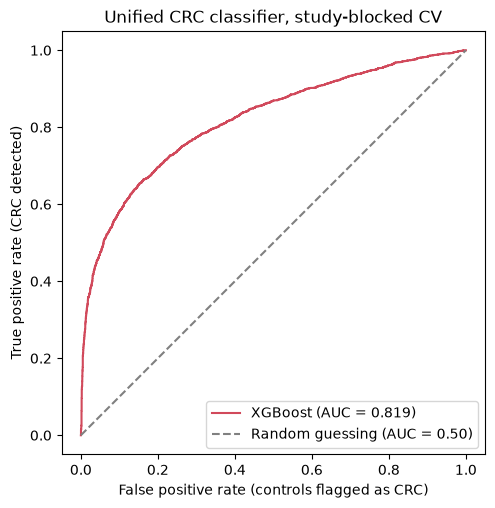

**Figure 1.** ROC curve of XGBoost's median predictions for 5,966 samples. AUC = 0.819, against 0.808 for the 2A random forest (+0.010) and 0.84 in the paper (-0.021). The single repeats range from 0.800 to 0.818. At a 10% false positive rate the model detects 58% of CRC samples.

In [7]:
false_positive_rate, true_positive_rate, _ = roc_curve(y, median_prediction)

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(false_positive_rate, true_positive_rate, color="#D1495B", label=f"XGBoost (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random guessing (AUC = 0.50)")
ax.set_xlabel("False positive rate (controls flagged as CRC)")
ax.set_ylabel("True positive rate (CRC detected)")
ax.set_title("Unified CRC classifier, study-blocked CV")
ax.legend(loc="lower right")
ax.set_aspect("equal")

detected_at_10_percent = true_positive_rate[np.searchsorted(false_positive_rate, 0.10, side="right") - 1]
show_figure(
    fig,
    "roc_unified",
    f"ROC curve of XGBoost's median predictions for {len(y):,} samples. AUC = {auc:.3f}, against "
    f"{AUC_2A:.3f} for the 2A random forest ({auc - AUC_2A:+.3f}) and {AUC_PAPER} in the paper ({auc - AUC_PAPER:+.3f}). "
    f"The single repeats range from {min(auc_per_repeat):.3f} to {max(auc_per_repeat):.3f}. At a 10% false positive "
    f"rate the model detects {detected_at_10_percent:.0%} of CRC samples.",
)

## 4. Leave-one-study-out (LOSO)

As in 2A: train on 26 studies, test on the one left out, once per study. The tuning runs inside the 26 training studies, with the same inner loop as above.

In [8]:
start = time.perf_counter()
loso_rows = []
for study in studies:
    is_held_out = groups == study
    test_scores, best_params, inner_auc = tune_and_predict(np.flatnonzero(~is_held_out), np.flatnonzero(is_held_out))
    loso_rows.append({"study": study, "n_test": int(is_held_out.sum()), "auc": roc_auc_score(y[is_held_out], test_scores)})
    chosen_rows.append({"split": f"loso_{study}", "inner_auc": inner_auc, **best_params})
print(f"Tuned {len(studies)} LOSO models in {time.perf_counter() - start:.0f} s")

loso = pd.DataFrame(loso_rows).set_index("study")
loso["auc_2a"] = loso_2a["our_auc"].reindex(loso.index)
loso["auc_paper"] = loso_2a["paper_auc"].reindex(loso.index)
if not QUICK:
    loso.round(4).to_csv(TABLES / "loso_auc.csv")

difference_2a = loso["auc"] - loso["auc_2a"]
in_paper = loso["auc_paper"].notna()
print(f"LOSO mean AUC over the {in_paper.sum()} studies in the paper's Table S5: {loso.loc[in_paper, 'auc'].mean():.3f} "
      f"(2A {loso.loc[in_paper, 'auc_2a'].mean():.3f}, paper {loso.loc[in_paper, 'auc_paper'].mean():.3f})")
print(f"Better than 2A in {(difference_2a > 0).sum()} of {len(loso)} studies, mean difference {difference_2a.mean():+.3f}")
loso.round(3).sort_values("auc")

d:\Projects\University\graduation_thesis\.venv\Lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Tuned 27 LOSO models in 9314 s
LOSO mean AUC over the 26 studies in the paper's Table S5: 0.840 (2A 0.836, paper 0.851)
Better than 2A in 17 of 27 studies, mean difference +0.005


,n_test,auc,auc_2a,auc_paper
study,,,,
YoungC2_2021,606,0.634,0.606,0.794
YachidaS_2019,498,0.741,0.734,0.745
HanniganGD_2018,32,0.742,0.709,0.707
BaxterNT_2016,240,0.758,0.759,0.778
VogtmannE_2016,104,0.777,0.769,0.782
ThomasAM_2019_1,48,0.795,0.833,0.819
YoungC1_2021,80,0.803,0.797,0.861
YangY_2021c,198,0.819,0.813,0.819
ZellerG_2014,104,0.826,0.838,0.852


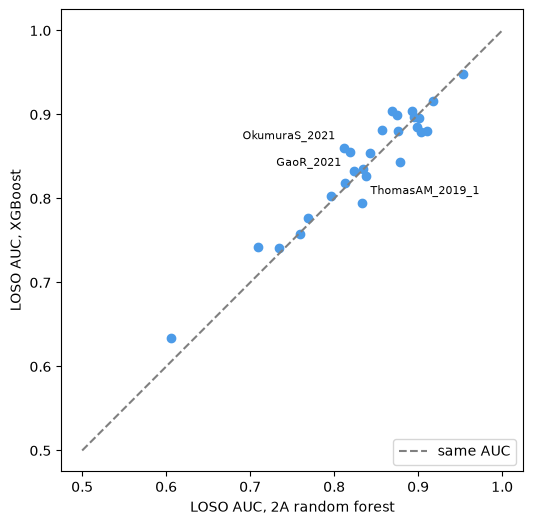

**Figure 2.** LOSO AUC per held-out study, XGBoost against the 2A random forest (27 studies). Points above the line improved: 17 studies. Over the 26 studies in the paper's Table S5 the mean AUC is 0.840, against 0.836 for 2A and 0.851 in the paper. The largest change is OkumuraS_2021 (+0.049).

In [9]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(loso["auc_2a"], loso["auc"], color="#4C9BE8")
ax.plot([0.5, 1], [0.5, 1], color="grey", linestyle="--", label="same AUC")
labelled = loso.loc[difference_2a.abs().nlargest(3).index].sort_values("auc", ascending=False).index
for rank, study in enumerate(labelled):
    above = difference_2a[study] > 0
    ax.annotate(
        study,
        (loso.loc[study, "auc_2a"], loso.loc[study, "auc"]),
        fontsize=8,
        xytext=(-6 if above else 6, 4 if rank % 2 == 0 else -4),
        textcoords="offset points",
        ha="right" if above else "left",
        va="bottom" if rank % 2 == 0 else "top",
    )
ax.set_xlabel("LOSO AUC, 2A random forest")
ax.set_ylabel("LOSO AUC, XGBoost")
ax.legend(loc="lower right")
ax.set_aspect("equal")

show_figure(
    fig,
    "loso_vs_2a",
    f"LOSO AUC per held-out study, XGBoost against the 2A random forest ({len(loso)} studies). Points above the line "
    f"improved: {(difference_2a > 0).sum()} studies. Over the {in_paper.sum()} studies in the paper's Table S5 the mean AUC is "
    f"{loso.loc[in_paper, 'auc'].mean():.3f}, against {loso.loc[in_paper, 'auc_2a'].mean():.3f} for 2A and "
    f"{loso.loc[in_paper, 'auc_paper'].mean():.3f} in the paper. The largest change is {difference_2a.abs().idxmax()} ({difference_2a.loc[difference_2a.abs().idxmax()]:+.3f}).",
)

## 5. Which settings won

Each split picks one winner out of the same 10 candidates. If one candidate wins almost everywhere, the choice is stable. The histograms show the winning value of each setting across all splits.

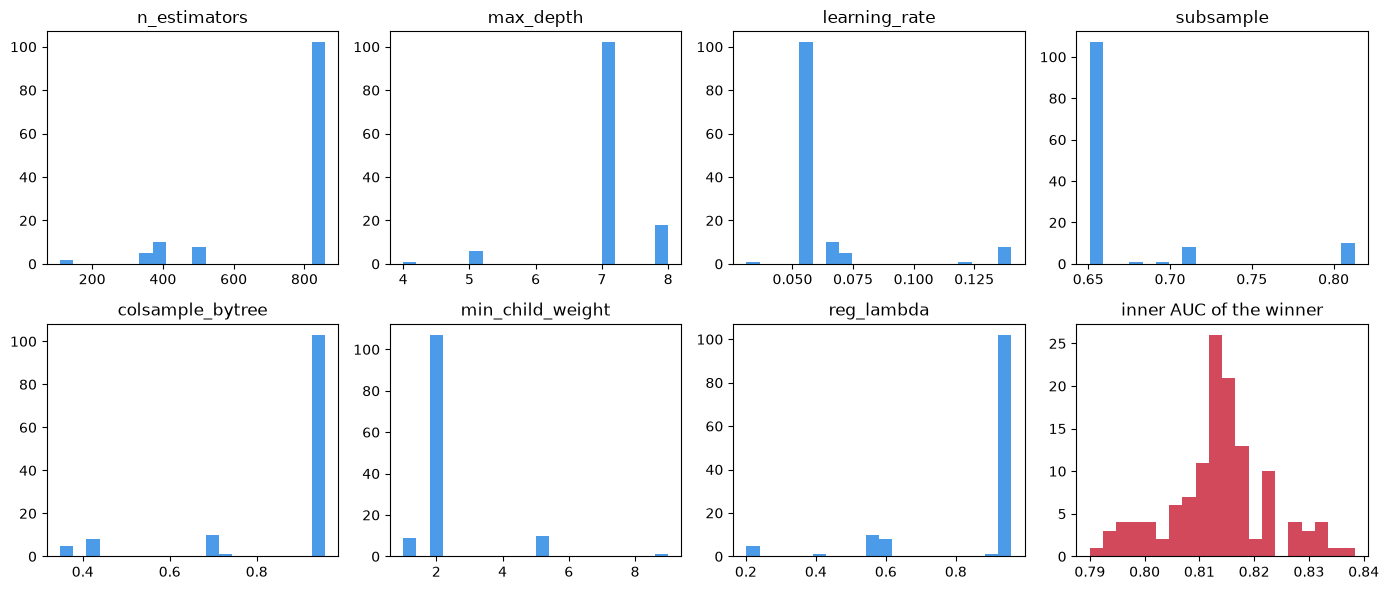

**Figure 3.** Winning value of each setting over 127 splits (100 unified, 27 LOSO). The most frequent winner won 102 splits: n_estimators = 858, max_depth = 7, learning_rate = 0.0556, subsample = 0.6585, colsample_bytree = 0.9569, min_child_weight = 2, reg_lambda = 0.9588. The inner AUC of the winners ranges from 0.790 to 0.838.

In [10]:
chosen_params = pd.DataFrame(chosen_rows).rename(columns=lambda name: name.removeprefix("model__"))
if not QUICK:
    chosen_params.to_csv(TABLES / "chosen_params.csv", index=False)

setting_names = list(SPACE_DESCRIPTION)
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, name in zip(axes.flat, setting_names):
    ax.hist(chosen_params[name], bins=20, color="#4C9BE8")
    ax.set_title(name)
axes.flat[-1].hist(chosen_params["inner_auc"], bins=20, color="#D1495B")
axes.flat[-1].set_title("inner AUC of the winner")
fig.tight_layout()

winner_counts = chosen_params[setting_names].round(4).value_counts()
show_figure(
    fig,
    "chosen_params",
    f"Winning value of each setting over {len(chosen_params)} splits ({len(chosen_params) - len(studies)} unified, {len(studies)} LOSO). "
    f"The most frequent winner won {winner_counts.iloc[0]} splits: "
    + ", ".join(f"{name} = {value}" for name, value in zip(setting_names, winner_counts.index[0]))
    + f". The inner AUC of the winners ranges from {chosen_params['inner_auc'].min():.3f} to {chosen_params['inner_auc'].max():.3f}.",
)

## 6. Experiment log (MLflow)

Every full run of this notebook (`QUICK = False`) saves one MLflow record: the seed, the search space, the git commit and the final AUCs, with this notebook's tables attached. Changing a range or the search size and running again adds a new record and keeps the old one, so every hyperparameter change is documented. To browse the records, run `mlflow ui --backend-store-uri sqlite:///mlflow.db` from the project root.

In [11]:
if QUICK:
    print("QUICK mode: test run, nothing logged to MLflow")
else:
    mlflow.set_tracking_uri(f"sqlite:///{(PROJECT_ROOT / 'mlflow.db').as_posix()}")
    EXPERIMENT = "phase-2b/02_xgboost"
    if mlflow.get_experiment_by_name(EXPERIMENT) is None:
        mlflow.create_experiment(EXPERIMENT, artifact_location=(PROJECT_ROOT / "mlruns").as_uri())
    mlflow.set_experiment(EXPERIMENT)

    git_commit = subprocess.run(["git", "rev-parse", "HEAD"], cwd=PROJECT_ROOT, capture_output=True, text=True).stdout.strip()
    with mlflow.start_run() as run:
        mlflow.log_params({"seed": SEED, "n_repeats": N_REPEATS, "n_iter": N_ITER,
                           "search_space": str(SPACE_DESCRIPTION), "git_commit": git_commit})
        mlflow.log_metrics({"unified_auc": auc, "loso_mean_auc": loso.loc[in_paper, "auc"].mean()})
        mlflow.log_artifacts(str(TABLES))
    print(f"Logged MLflow run {run.info.run_id} in experiment {EXPERIMENT}")

Logged MLflow run a2e53e0c5cba482a92faf4f9a09d535b in experiment phase-2b/02_xgboost


## 7. Checks

In [12]:
assert not QUICK, "the reported notebook must come from the full run"
for repeat in folds:
    for train_idx, test_idx in repeat:
        assert set(groups[train_idx]).isdisjoint(groups[test_idx]), "no study on both sides of an outer split"
        assert set(y[test_idx]) == {0, 1}
        for inner_train, inner_val in StratifiedGroupKFold(n_splits=3).split(train_idx, y[train_idx], groups[train_idx]):
            assert set(groups[train_idx][inner_train]).isdisjoint(groups[train_idx][inner_val]), "no study on both sides of an inner split"
assert predictions.shape == (5966, N_REPEATS)
assert not np.isnan(predictions).any(), "every sample is tested once per repeat"
assert len(loso) == 27
assert len(chosen_params) == len(folds) * 10 + 27
assert 0.5 < auc < 1
print("All checks passed.")

All checks passed.
